# Preprocessing zdjęcia liścia ziemniaka

Przykłady wszystkich opcji z `src/preprocessing/`. Każdą operację porównujemy z tym samym oryginałem. Na końcu łączymy wybrane kroki w pipeline.

Uruchom notebook od początku, używając środowiska projektu (`.venv`). Nie zmieniamy plików w `data/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from src.preprocessing.adjustment import (
    adjust_brightness,
    adjust_contrast,
    histogram_equalization,
)
from src.preprocessing.binarization import (
    apply_binarization,
    binarize_image,
    binarize_image_per_channel,
    calculate_otsu_threshold,
    calculate_otsu_threshold_per_channel,
    combine_binarized_channels,
)
from src.preprocessing.domain import PreprocessingSettings
from src.preprocessing.filtering import (
    apply_blur_filter,
    apply_gaussian_filter,
    apply_mean_filter,
    apply_median_filter,
    apply_sharpen_filter,
    filter_image,
)
from src.preprocessing.morphology import (
    apply_morphology,
    create_leaf_mask,
    remove_background,
)
from src.preprocessing.normalization import apply_normalization
from src.preprocessing.pipeline import preprocess_images


## Zdjęcie wejściowe

Wybieramy jedno zdjęcie chorego liścia. Można podmienić `image_path` na dowolną ścieżkę z `data/`.


data/Task 2 - Hard/Potato___Late_blight/0e7f0484-16eb-4183-b702-0a5b4f94d015___RS_LB 4000.JPG
Rozmiar: (256, 256) Tryb: RGB


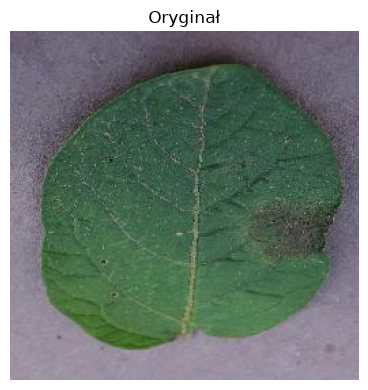

In [2]:
# image_path = sorted(Path("data/Task 1 - Simple/Potato___Early_blight").glob("*.JPG"))[0]
image_path = Path("data/Task 2 - Hard/Potato___Late_blight/0e7f0484-16eb-4183-b702-0a5b4f94d015___RS_LB 4000.JPG")
with Image.open(image_path) as source:
    image = source.convert("RGB")

print(image_path)
print("Rozmiar:", image.size, "Tryb:", image.mode)


def show_images(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        if np.asarray(img).ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_images([image], ["Oryginał"])


## Jasność i kontrast

`factor=1.0` zachowuje obraz. Wartości poniżej 1 zmniejszają jasność lub kontrast, a powyżej 1 je zwiększają.


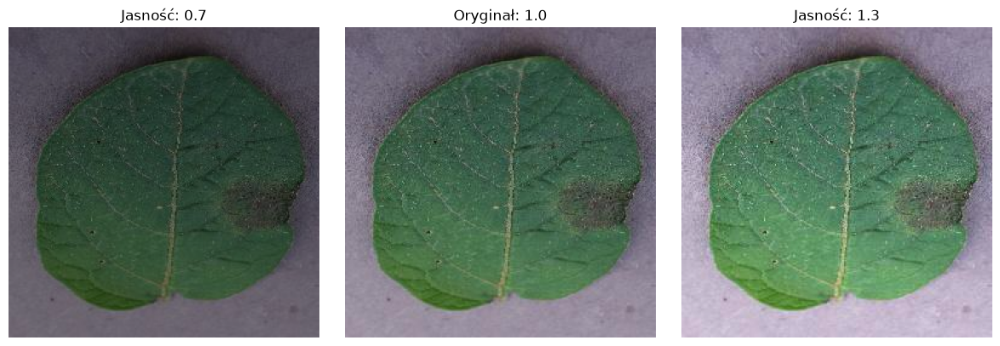

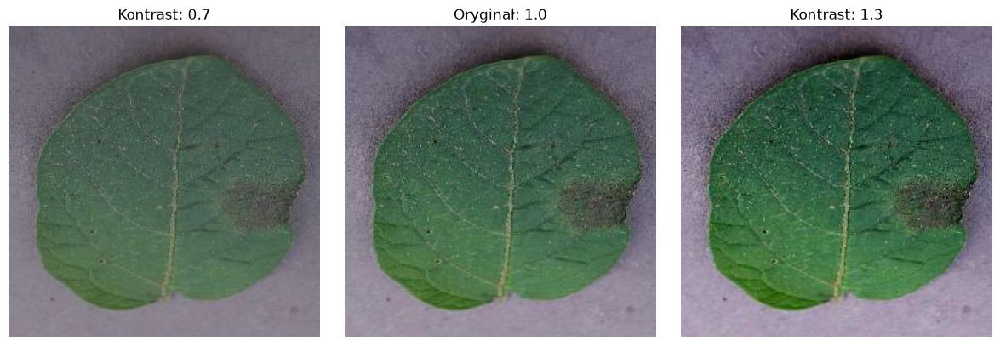

In [3]:
show_images(
    [adjust_brightness(image, 0.7), image, adjust_brightness(image, 1.3)],
    ["Jasność: 0.7", "Oryginał: 1.0", "Jasność: 1.3"],
)
show_images(
    [adjust_contrast(image, 0.7), image, adjust_contrast(image, 1.3)],
    ["Kontrast: 0.7", "Oryginał: 1.0", "Kontrast: 1.3"],
)


## Automatyczne wyrównanie jasności i kontrastu

`factor="auto"` dopasowuje statystyki jasności do wspólnych wartości referencyjnych. Jasność jest średnią kanału Y w YCbCr, a kontrast jego odchyleniem standardowym. Dla obrazów w skali szarości używany jest kanał L.

- `adjust_brightness(..., "auto", reference=128)` przesuwa jasność do średniej 128.
- `adjust_contrast(..., "auto", reference=40)` skaluje kontrast wokół aktualnej średniej, celując w odchylenie 40.
- Opcjonalny `mask` ogranicza obliczenia i zmianę obrazu do liścia. Poza maską piksele pozostają bez zmian.

Skala referencji to 0–255. Wartości 128 i 40 to ustawienia startowe, nie wyznaczone optimum klasyfikacji. Można je zmienić lub wyznaczyć ze zdjęcia referencyjnego ze zbioru treningowego. Nie obliczamy referencji na zbiorze testowym.

Operacje zmieniają jasność przy zachowaniu kanałów chromatycznych. Obcięcie wartości do 0–255 i zaokrąglenie do liczb całkowitych mogą powodować odchylenia od celu. Obraz o stałej jasności nie ma szczegółów do wzmocnienia — auto kontrast pozostawia go bez zmian. Pusta maska również pozostawia obraz bez zmian.


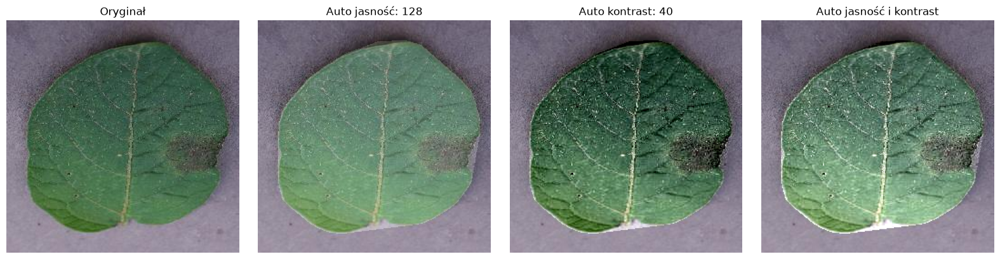

In [4]:
auto_mask = create_leaf_mask(image)
brightness_auto = adjust_brightness(image=image, factor="auto", reference=128.0, mask=auto_mask)
contrast_auto = adjust_contrast(image=image, factor="auto", reference=40.0, mask=auto_mask)
both_auto = adjust_contrast(brightness_auto, "auto", reference=40.0, mask=auto_mask)

show_images(
    [image, brightness_auto, contrast_auto, both_auto],
    ["Oryginał", "Auto jasność: 128", "Auto kontrast: 40", "Auto jasność i kontrast"],
)


## Wyrównanie histogramu

`histogram_equalization` stosuje CLAHE do jasności, bez osobnego wyrównywania kanałów RGB. Obsługuje też obrazy w skali szarości.


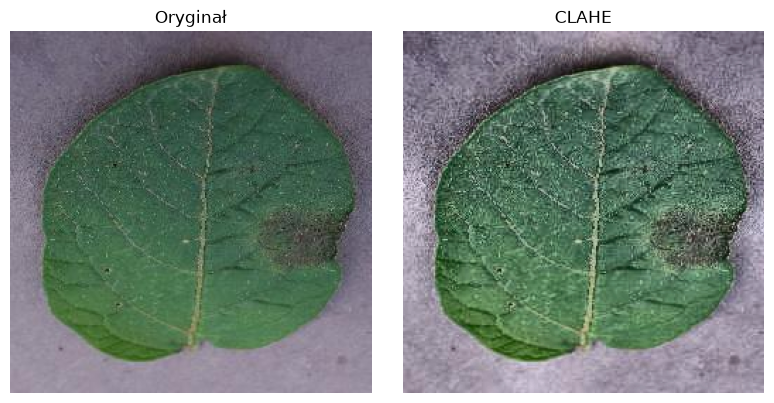

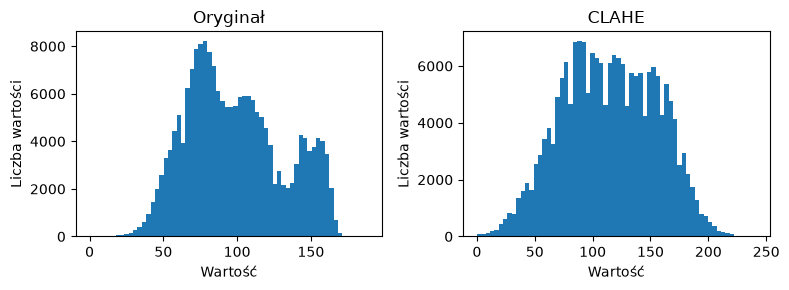

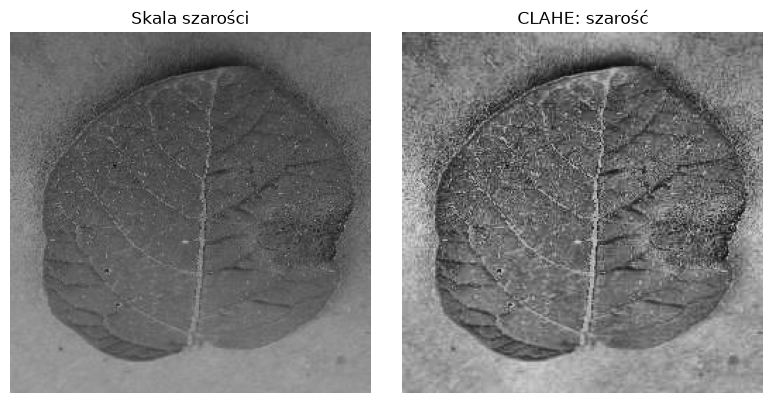

In [5]:
gray = image.convert("L")
show_images([image, histogram_equalization(image)], ["Oryginał", "CLAHE"])
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, pixels, title in zip(axes, [np.asarray(image), np.asarray(histogram_equalization(image))], ["Oryginał", "CLAHE"]):
    ax.hist(pixels.ravel(), bins=64)
    ax.set_title(title)
    ax.set_xlabel("Wartość")
    ax.set_ylabel("Liczba wartości")
plt.tight_layout()
plt.show()
show_images([gray, histogram_equalization(gray)], ["Skala szarości", "CLAHE: szarość"])


## Filtry

`filter_image` pozwala wybrać filtr przez nazwę: `gaussian`, `median`, `mean`, `sharpen` lub `blur`. Domyślny Gaussian ma `sigma=0.5`, a median i mean używają okna 3×3.


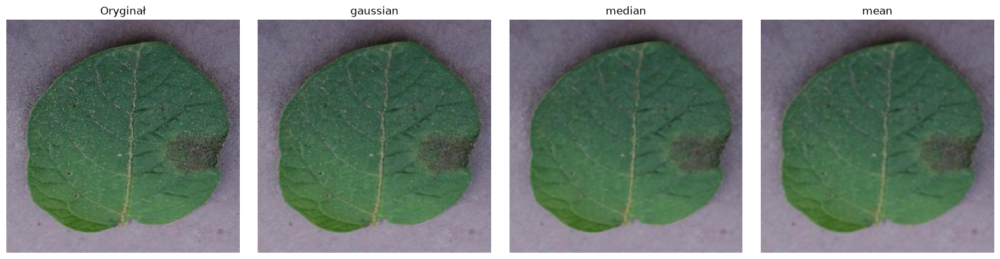

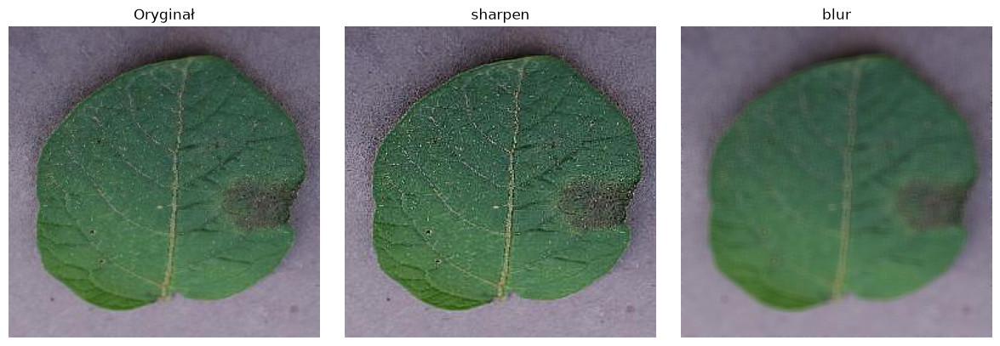

In [6]:
for names in [("gaussian", "median", "mean"), ("sharpen", "blur")]:
    show_images(
        [image] + [filter_image(image, name) for name in names],
        ["Oryginał"] + list(names),
    )


Można też wywołać filtry bezpośrednio. Większa `sigma` lub większe nieparzyste `size` mocniej wygładzają obraz, ale mogą usuwać drobne zmiany chorobowe.


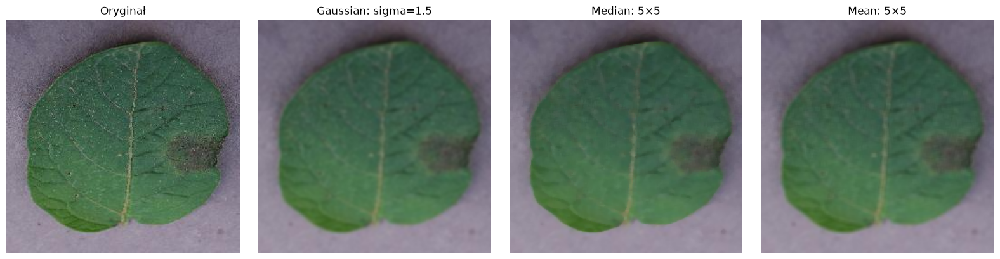

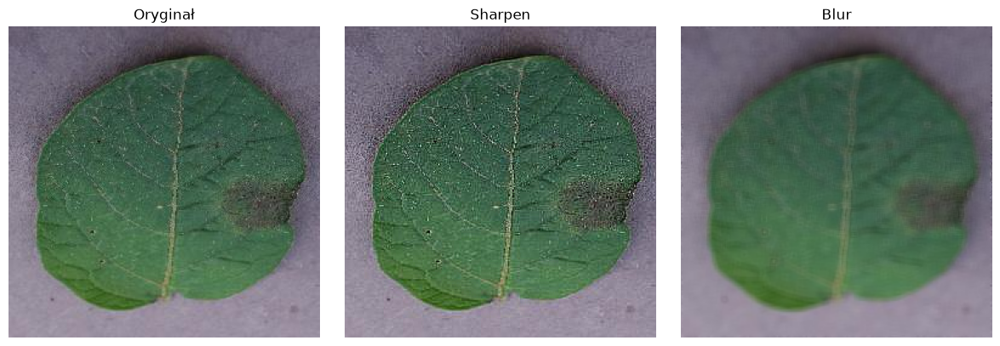

In [7]:
show_images(
    [image, apply_gaussian_filter(image, sigma=1.5),
     apply_median_filter(image, size=5), apply_mean_filter(image, size=5)],
    ["Oryginał", "Gaussian: sigma=1.5", "Median: 5×5", "Mean: 5×5"],
)
show_images(
    [image, apply_sharpen_filter(image), apply_blur_filter(image)],
    ["Oryginał", "Sharpen", "Blur"],
)


## Normalizacja

Obie metody zwracają tablicę NumPy `float32` i używają wspólnej skali dla RGB:

- `min-max`: wartości od 0 do 1;
- `z-score`: średnia około 0 i odchylenie standardowe około 1.

Z-score zawiera wartości ujemne, więc nie przekazujemy go bezpośrednio do `imshow` jako RGB. Tylko do podglądu przeliczamy go na zakres `[0, 1]`. Taki podgląd nie pokazuje różnicy skali — pokazują ją statystyki i histogramy. Do dalszych obliczeń używamy oryginalnej tablicy `z_score`.


Oryginał: uint8, min=0.000, max=189.000, średnia=98.608, std=32.728
Min-max: float32, min=0.000, max=1.000, średnia=0.522, std=0.173
Z-score: float32, min=-3.013, max=2.762, średnia=-0.000, std=1.000


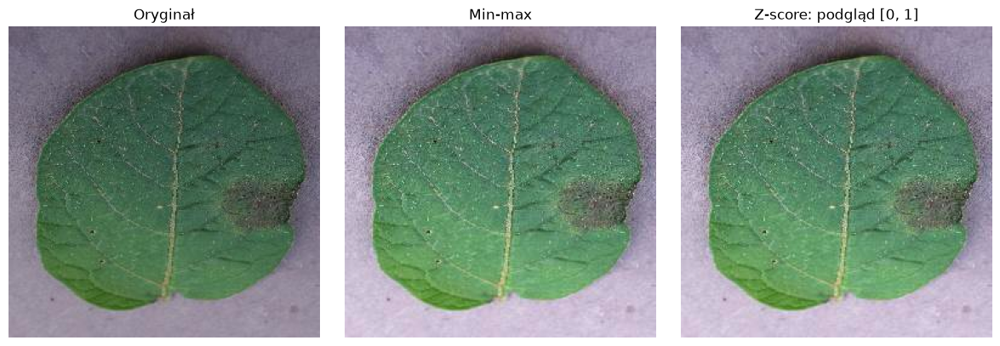

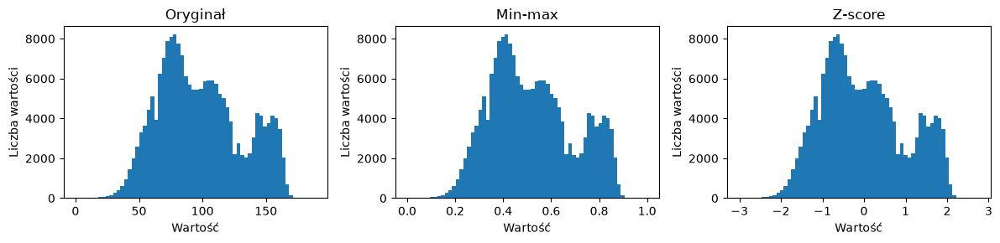

In [8]:
min_max = apply_normalization(image, "min-max")
z_score = apply_normalization(image, "z-score")
z_score_view = (z_score - z_score.min()) / (z_score.max() - z_score.min())

for name, pixels in [("Oryginał", np.asarray(image)), ("Min-max", min_max), ("Z-score", z_score)]:
    print(f"{name}: {pixels.dtype}, min={pixels.min():.3f}, max={pixels.max():.3f}, "
          f"średnia={pixels.mean():.3f}, std={pixels.std():.3f}")

show_images([image, min_max, z_score_view], ["Oryginał", "Min-max", "Z-score: podgląd [0, 1]"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, pixels, title in zip(axes, [np.asarray(image), min_max, z_score], ["Oryginał", "Min-max", "Z-score"]):
    ax.hist(pixels.ravel(), bins=64)
    ax.set_title(title)
    ax.set_xlabel("Wartość")
    ax.set_ylabel("Liczba wartości")
plt.tight_layout()
plt.show()


## Binaryzacja w skali szarości

Piksele większe od progu stają się białe (255), pozostałe czarne (0). `calculate_otsu_threshold` dobiera próg automatycznie. Wynik jest obrazem PIL w trybie `L`.


Próg Otsu: 114


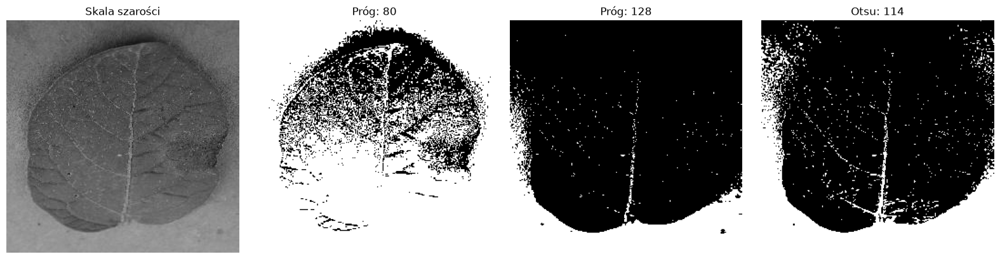

In [9]:
otsu_threshold = calculate_otsu_threshold(image)
print("Próg Otsu:", otsu_threshold)

show_images(
    [gray, binarize_image(image, 80), binarize_image(image, 128),
     binarize_image(image, otsu_threshold)],
    ["Skala szarości", "Próg: 80", "Próg: 128", f"Otsu: {otsu_threshold}"],
)


## Binaryzacja per channel: R, G i B osobno

Najpierw pokazujemy wejściowe kanały jako trzy obrazy w skali szarości. Jasność oznacza wartość danego kanału.


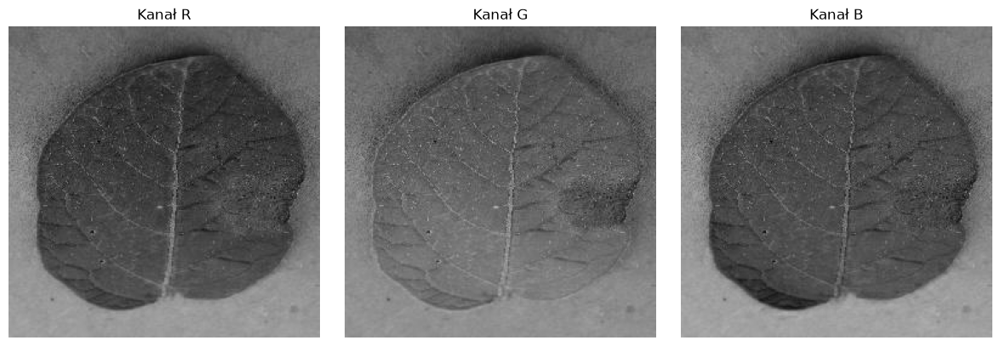

In [10]:
show_images(list(image.split()), ["Kanał R", "Kanał G", "Kanał B"])


### Ręczne progi

`binarize_image_per_channel` przyjmuje trzy progi w kolejności `(R, G, B)` i zwraca trzy osobne obrazy PIL. Każdy kanał wyświetlamy osobno.


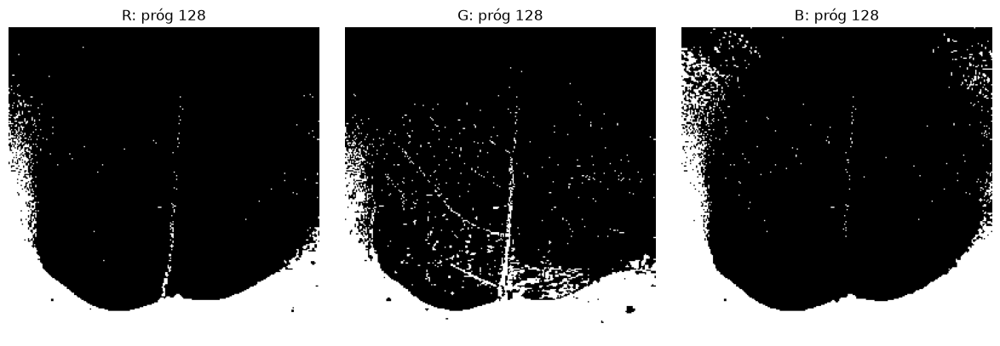

In [11]:
thresholds = (128, 128, 128)
channels = binarize_image_per_channel(image, thresholds)
red, green, blue = channels

show_images(
    [red, green, blue],
    [f"R: próg {thresholds[0]}", f"G: próg {thresholds[1]}", f"B: próg {thresholds[2]}"],
)


### Otsu dla każdego kanału

Każdy kanał otrzymuje własny próg. Wyniki nadal są trzema osobnymi obrazami, a nie jednym obrazem RGB.


Progi Otsu (R, G, B): (99, 110, 106)


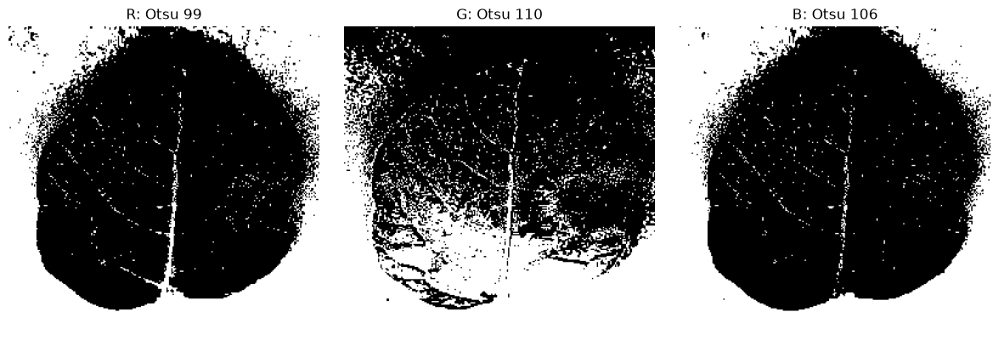

In [12]:
otsu_thresholds = calculate_otsu_threshold_per_channel(image)
otsu_channels = binarize_image_per_channel(image, otsu_thresholds)
print("Progi Otsu (R, G, B):", otsu_thresholds)

show_images(
    list(otsu_channels),
    [f"R: Otsu {otsu_thresholds[0]}", f"G: Otsu {otsu_thresholds[1]}",
     f"B: Otsu {otsu_thresholds[2]}"],
)


### Łączenie kanałów i skrót `apply_binarization`

`combine_binarized_channels` składa trzy maski w obraz RGB. Kolory takiego obrazu oznaczają kombinacje masek, nie barwy liścia.

`apply_binarization` wykonuje te kroki jednym wywołaniem. `threshold=None` oznacza Otsu, a liczba ustawia stały próg. Przy `per_channel=True` stały próg jest wspólny dla R, G i B; Otsu wyznacza trzy różne progi.


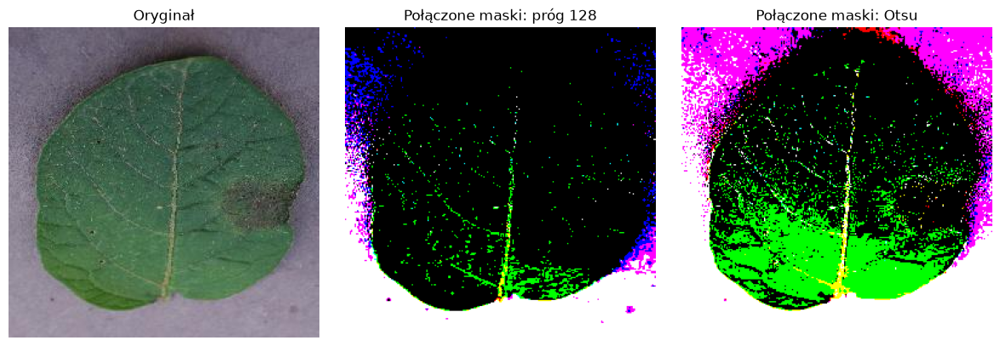

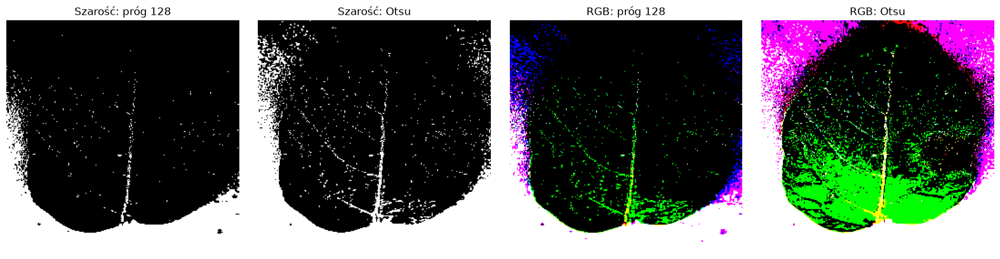

In [13]:
show_images(
    [image, combine_binarized_channels(channels), combine_binarized_channels(otsu_channels)],
    ["Oryginał", "Połączone maski: próg 128", "Połączone maski: Otsu"],
)
show_images(
    [apply_binarization(image, threshold=128), apply_binarization(image),
     apply_binarization(image, threshold=128, per_channel=True),
     apply_binarization(image, per_channel=True)],
    ["Szarość: próg 128", "Szarość: Otsu", "RGB: próg 128", "RGB: Otsu"],
)


## Morfologia masek binarnych

Operacje działają na białych obszarach maski. `opening` usuwa drobne białe punkty, `closing` zamyka małe czarne szczeliny. `erosion` zmniejsza białe obszary, a `dilation` je powiększa. `opening-closing` wykonuje opening, a następnie closing.

W obrazie RGB każdy kanał jest przetwarzany osobno. `kernel_size` musi być dodatni i nieparzysty. Zbyt duże jądro może usunąć drobne zmiany chorobowe, dlatego zaczynamy od 3×3.


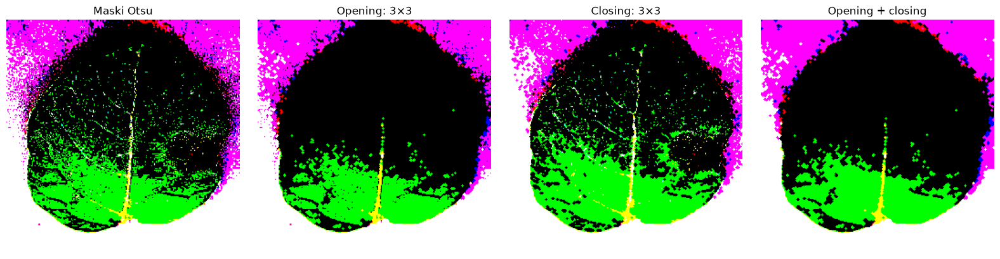

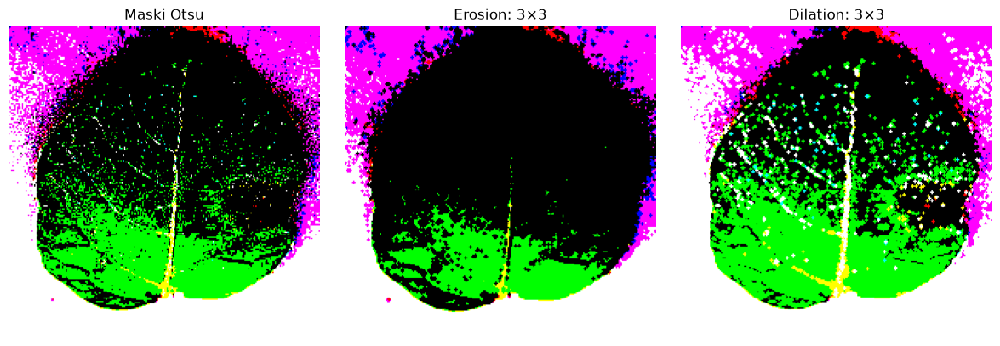

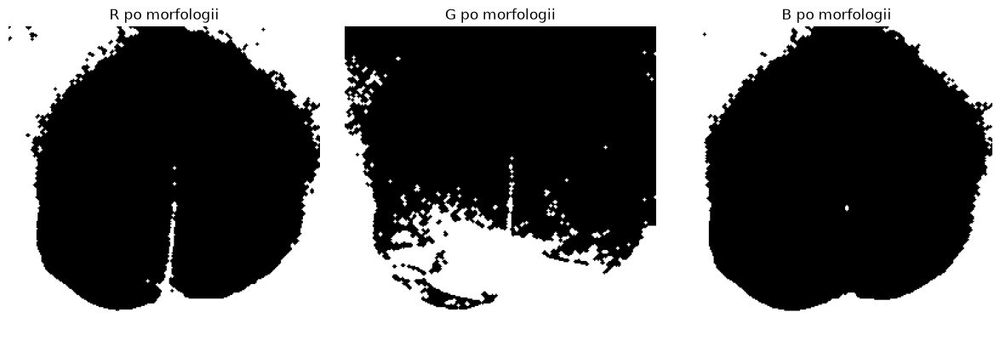

In [14]:
combined_mask = combine_binarized_channels(otsu_channels)
opened = apply_morphology(combined_mask, "opening", kernel_size=3)
closed = apply_morphology(combined_mask, "closing", kernel_size=3)
cleaned = apply_morphology(combined_mask, "opening-closing", kernel_size=3)

show_images(
    [combined_mask, opened, closed, cleaned],
    ["Maski Otsu", "Opening: 3×3", "Closing: 3×3", "Opening + closing"],
)
show_images(
    [combined_mask, apply_morphology(combined_mask, "erosion"),
     apply_morphology(combined_mask, "dilation")],
    ["Maski Otsu", "Erosion: 3×3", "Dilation: 3×3"],
)
show_images(list(cleaned.split()), ["R po morfologii", "G po morfologii", "B po morfologii"])


## Usunięcie tła z zachowaniem całego liścia

Samo czyszczenie kanałów RGB nie oddziela tła od liścia. `create_leaf_mask` wyznacza maskę z połączenia dwóch masek Otsu: nasycenia HSV (kolorowe fragmenty, w tym brązowe plamy) i kanału a w Lab (zielone fragmenty, także słabo nasycone). Następnie wykonuje opening i closing, a następnie wypełnia otoczkę wypukłą największego zewnętrznego konturu. Zachowuje to ciemne i odbarwione plamy wewnątrz liścia oraz przy brzegu, nawet jeśli ich wycięcia łączą się z tłem. Otoczka może też zachować tło we wklęsłych fragmentach obrysu.

To prosta metoda dla pojedynczego kolorowego liścia na szarym tle, jak w tych danych. Może pominąć fragment niewykryty przez segmentację lub zachować kolorowy fragment tła. Nie gwarantuje idealnej segmentacji każdego zdjęcia.

`remove_background` nakłada maskę na oryginał lub na połączone maski binarne. Tło staje się czarne; obraz nie jest przezroczysty.


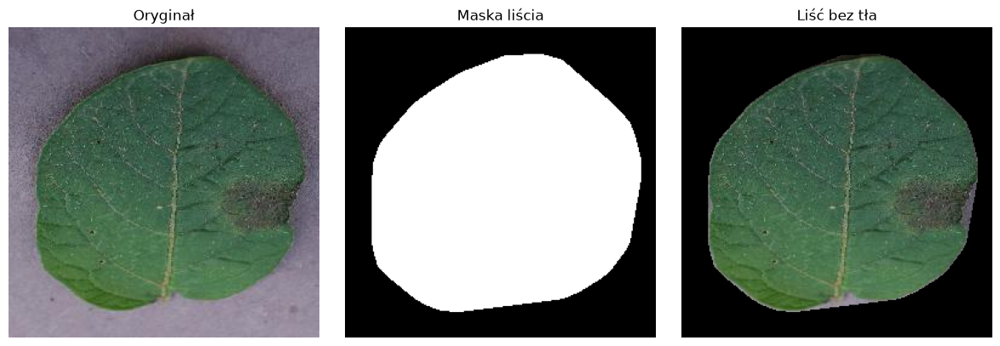

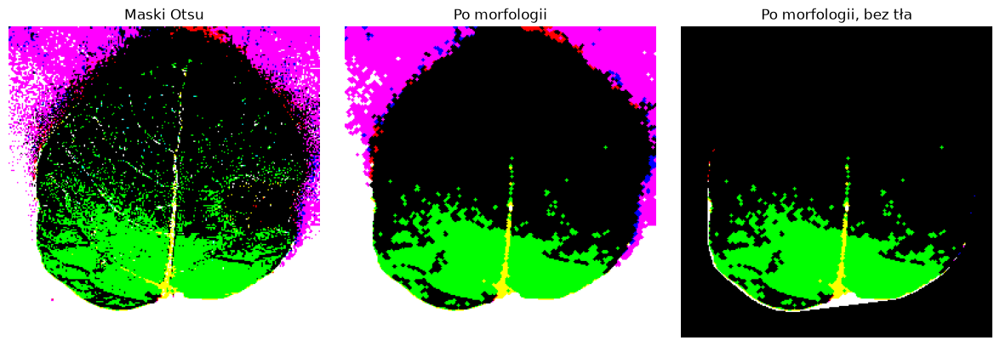

In [15]:
leaf_mask = create_leaf_mask(image, opening_size=3, closing_size=7)
leaf = remove_background(image, leaf_mask)
cleaned_leaf = remove_background(cleaned, leaf_mask)

show_images([image, leaf_mask, leaf], ["Oryginał", "Maska liścia", "Liść bez tła"])
show_images(
    [combined_mask, cleaned, cleaned_leaf],
    ["Maski Otsu", "Po morfologii", "Po morfologii, bez tła"],
)


### Przykłady z każdego katalogu

Jedno zdjęcie z każdej klasy i każdego zadania. Bez podania maski `remove_background` oblicza ją samodzielnie.


data/Task 1 - Simple/Potato___Early_blight


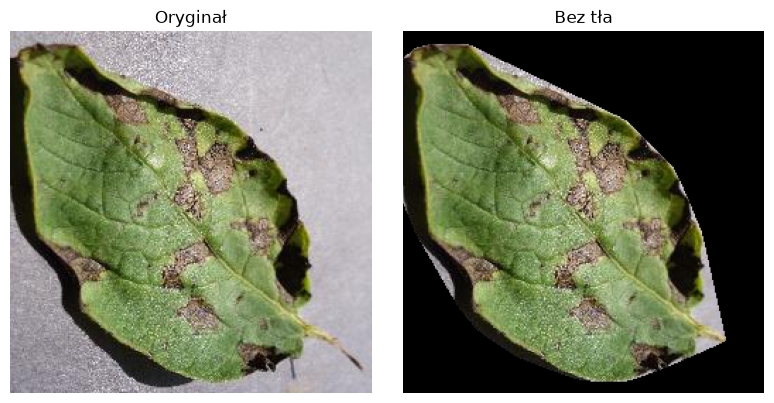

data/Task 1 - Simple/Potato___healthy


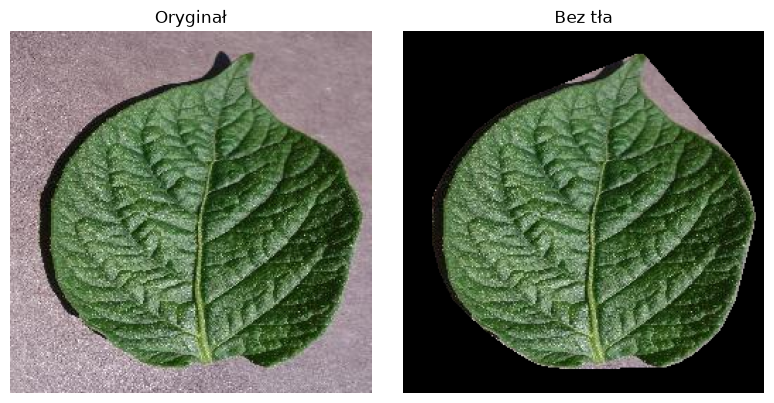

data/Task 2 - Hard/Potato___Early_blight


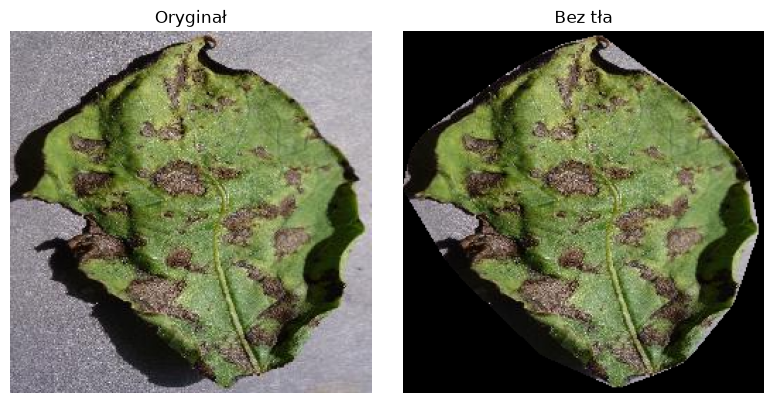

data/Task 2 - Hard/Potato___Late_blight


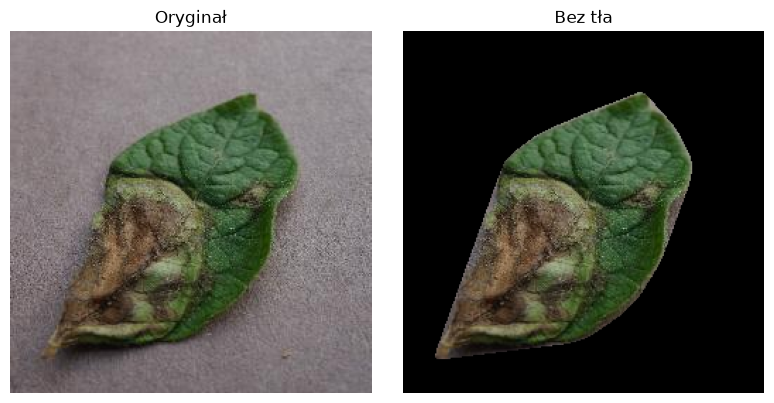

In [16]:
for folder in sorted(Path("data").glob("*/*")):
    if not folder.is_dir():
        continue
    sample_path = min(folder.glob("*.JPG"))
    with Image.open(sample_path) as source:
        sample = source.convert("RGB")
    print(folder)
    show_images([sample, remove_background(sample)], ["Oryginał", "Bez tła"])


## Etap wyznaczania maski liścia

`leaf_mask_stage` wybiera obraz, z którego powstanie maska usuwania tła:

| Wartość | Moment obliczenia maski |
| --- | --- |
| `"start"` | Po konwersji do RGB, przed zmianami jasności i kontrastu; wariant domyślny. |
| `"after_adjustment"` | Po regulacji jasności i kontrastu. |
| `"after_filtering"` | Po filtrowaniu, przed CLAHE. |
| `"after_equalization"` | Po CLAHE, przed binaryzacją i morfologią. |

Maska jest obliczana raz, a nakładana po binaryzacji i morfologii, przed normalizacją. Gdy wybrany krok jest wyłączony, maska powstaje w tym miejscu z aktualnego obrazu. Przy `remove_background=False` ustawienie jest pomijane.

Przy `"start"` korekty `"auto"` mogą korzystać z maski liścia. Przy późniejszych etapach korekty auto obejmują cały obraz, bo maska jeszcze nie powstała. Poniżej stosujemy ręczne korekty, żeby porównać sam wpływ etapu segmentacji na końcowy wynik.


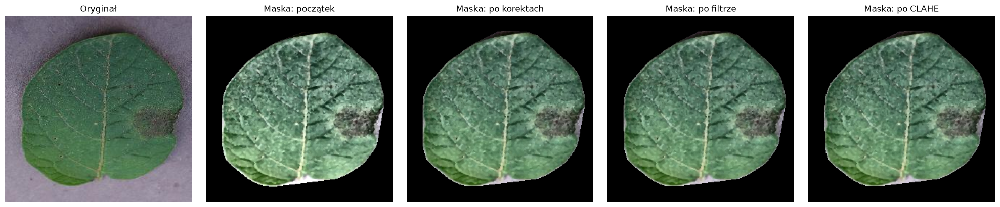

In [17]:
mask_stages = {
    "start": "Maska: początek",
    "after_adjustment": "Maska: po korektach",
    "after_filtering": "Maska: po filtrze",
    "after_equalization": "Maska: po CLAHE",
}

stage_results = []
for stage in mask_stages:
    stage_settings = PreprocessingSettings(
        brightness_adjustment="auto",
        contrast_adjustment="auto",
        filter_type="median",
        histogram_equalization=True,
        remove_background=True,
        leaf_mask_stage=stage,
        normalize=False,
    )
    stage_results.append(preprocess_images([image], stage_settings)[0])

show_images([image] + stage_results, ["Oryginał"] + list(mask_stages.values()))


## Pełny pipeline

Kolejność: orientacja EXIF i RGB → jasność → kontrast → filtr → CLAHE → opcjonalna binaryzacja → opcjonalna morfologia → opcjonalne usunięcie tła → opcjonalna normalizacja. Etap wyznaczania maski liścia wybiera `leaf_mask_stage`; domyślnie jest to oryginał przed zmianą jasności i kontrastu.

`preprocess_images` przyjmuje listę obrazów i zwraca listę wyników. Domyślnie zachowuje kolor: stosuje Gaussian, CLAHE i min–max, bez binaryzacji.


PreprocessingSettings(brightness_adjustment=1.0, contrast_adjustment=1.0, brightness_reference=128.0, contrast_reference=40.0, histogram_equalization=True, normalize=True, normalization_method='min-max', apply_filter=True, filter_type='gaussian', binarize=False, binarize_per_channel=True, apply_morphology=False, morphology_operation='opening-closing', morphology_kernel_size=3, remove_background=False, leaf_mask_stage='start')
Wynik: ndarray float32 (256, 256, 3)


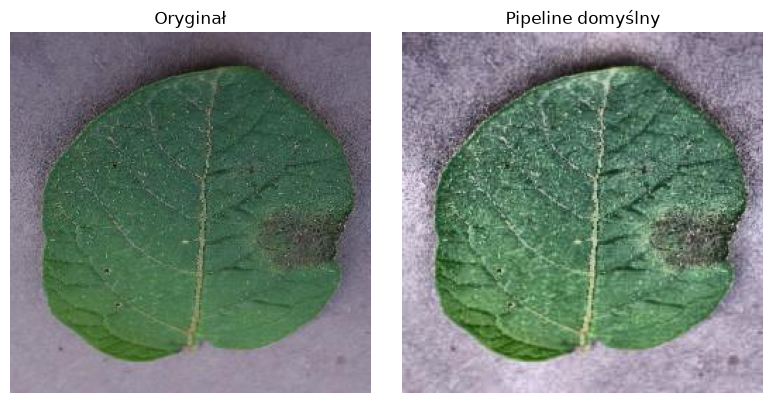

In [18]:
default_settings = PreprocessingSettings()
default_result = preprocess_images([image], default_settings)[0]
print(default_settings)
print("Wynik:", type(default_result).__name__, default_result.dtype, default_result.shape)
show_images([image, default_result], ["Oryginał", "Pipeline domyślny"])


### Własne ustawienia

Poniżej ustawiamy wszystkie opcje jawnie. Wyłączenie normalizacji pozostawia wynik jako obraz PIL. Wyłączenie binaryzacji zachowuje ciągłe wartości koloru i tekstury.


Wynik: Image RGB


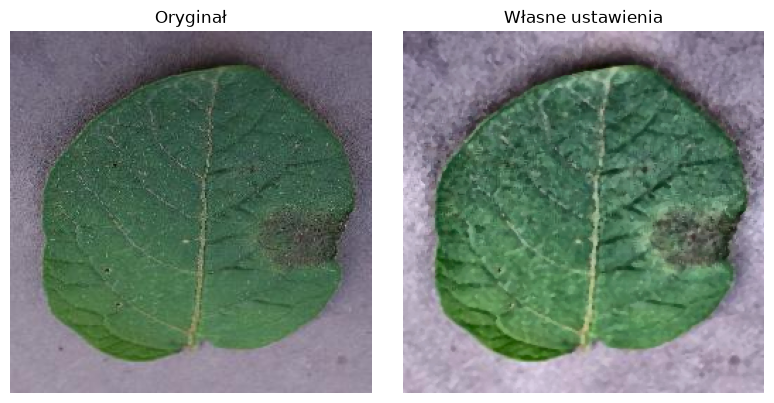

In [19]:
settings = PreprocessingSettings(
    brightness_adjustment=1.1,
    contrast_adjustment=1.1,
    histogram_equalization=True,
    normalize=False,
    normalization_method="min-max",
    apply_filter=True,
    filter_type="median",
    binarize=False,
    binarize_per_channel=True,
)
result = preprocess_images([image], settings)[0]
print("Wynik:", type(result).__name__, result.mode)
show_images([image, result], ["Oryginał", "Własne ustawienia"])


### Włączanie i wyłączanie kroków

Dwa przykłady binaryzacji w pipeline oraz wariant bez filtrów, CLAHE, binaryzacji i normalizacji. Z-score można wybrać przez `normalization_method="z-score"`.


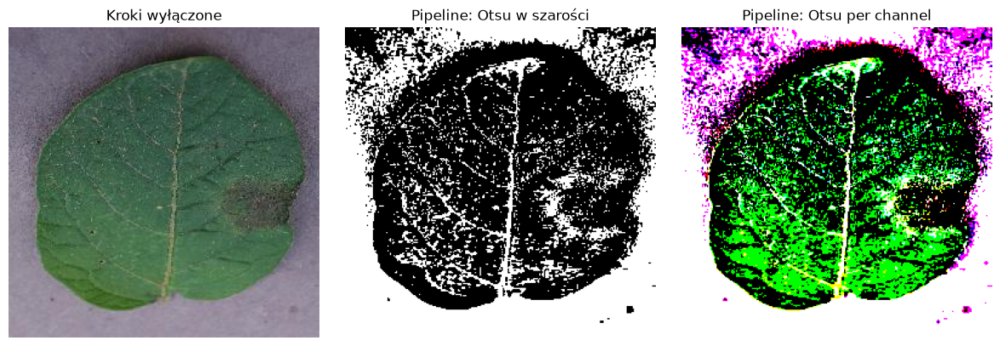

Pipeline z-score: średnia=0.000, std=1.000


In [20]:
settings_off = PreprocessingSettings(
    histogram_equalization=False, apply_filter=False, binarize=False, normalize=False,
)
settings_gray = PreprocessingSettings(
    binarize=True, binarize_per_channel=False, normalize=False,
)
settings_rgb = PreprocessingSettings(
    binarize=True, binarize_per_channel=True, normalize=False,
)

show_images(
    [preprocess_images([image], settings)[0] for settings in [settings_off, settings_gray, settings_rgb]],
    ["Kroki wyłączone", "Pipeline: Otsu w szarości", "Pipeline: Otsu per channel"],
)

settings_z_score = PreprocessingSettings(normalization_method="z-score")
normalized_result = preprocess_images([image], settings_z_score)[0]
print(f"Pipeline z-score: średnia={normalized_result.mean():.3f}, std={normalized_result.std():.3f}")


Binaryzacja usuwa część informacji o kolorze i teksturze, więc warto traktować ją jako osobny wariant do porównania. To demonstracja efektów; wybór ustawień dla klasyfikatora wymaga porównania wyników na zbiorze walidacyjnym.


### Pipeline z usuwaniem tła i morfologią

`remove_background=True` usuwa tło. `apply_morphology=True` czyści wynik binaryzacji, więc wymaga `binarize=True`. Oba kroki są domyślnie wyłączone.

Wariant kolorowy zachowuje teksturę i barwy liścia. Warianty binarne pokazują działanie morfologii osobno dla szarości i RGB. Wyłączamy normalizację, aby tło w wynikach pozostało równe 0. Z-score zmieni również wartość czarnego tła.


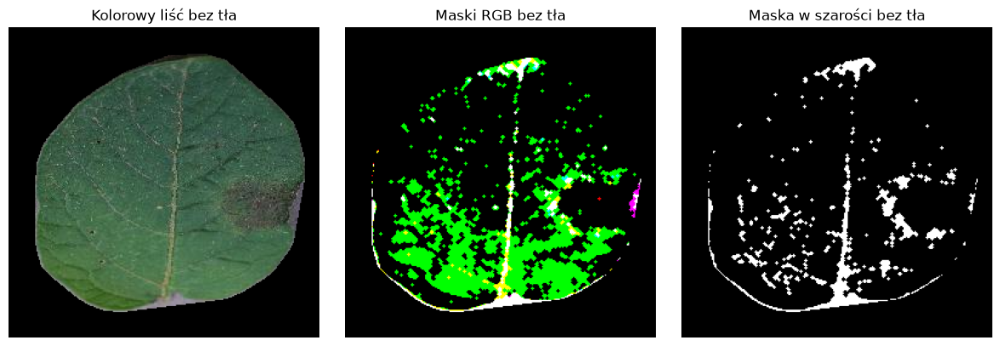

In [21]:
color_settings = PreprocessingSettings(
    histogram_equalization=False,
    apply_filter=False,
    normalize=False,
    remove_background=True,
)
binary_settings = PreprocessingSettings(
    binarize=True,
    binarize_per_channel=True,
    apply_morphology=True,
    morphology_operation="opening-closing",
    morphology_kernel_size=3,
    remove_background=True,
    normalize=False,
)
gray_settings = PreprocessingSettings(
    binarize=True,
    binarize_per_channel=False,
    apply_morphology=True,
    remove_background=True,
    normalize=False,
)

show_images(
    [preprocess_images([image], settings)[0]
     for settings in [color_settings, binary_settings, gray_settings]],
    ["Kolorowy liść bez tła", "Maski RGB bez tła", "Maska w szarości bez tła"],
)


## Rekomendowane ustawienia przed ekstrakcją cech

Poniższe pięć wariantów to kandydaci do porównania, a nie potwierdzony ranking skuteczności. Bez ekstrakcji cech i walidacji klasyfikatora nie można ustalić, który maksymalizuje trafność. Tutaj oceniamy wizualnie zachowanie barw, tekstury i kształtu liścia po całym pipeline.

We wszystkich wariantach usuwamy tło i stosujemy normalizację `min-max`. Jasność i kontrast pozostają na poziomie `1.0`. Wyniki są tablicami `float32` w zakresie `[0, 1]`, gotowymi do dalszych obliczeń. Morfologia używana przy tworzeniu maski liścia działa także wtedy, gdy `apply_morphology=False`; ta opcja steruje dodatkowym czyszczeniem obrazu po binaryzacji.

| Wariant | Filtr | CLAHE | Binaryzacja | Morfologia binaryzacji | Zastosowanie i kompromis |
| --- | --- | --- | --- | --- | --- |
| 1. Kolor i detale | Brak | Nie | Nie | Nie | Punkt wyjścia dla cech barwy i drobnej tekstury. Zachowuje również szum. |
| 2. Łagodne wygładzenie | Gaussian, sigma=0.5 | Nie | Nie | Nie | Ogranicza drobny szum bez wyrównywania jasności. Może osłabić najmniejsze szczegóły. |
| 3. Lokalny kontrast | Gaussian, sigma=0.5 | Tak | Nie | Nie | Kandydat przy nierównym oświetleniu i słabo widocznych plamach. CLAHE zmienia rozkład jasności. |
| 4. Filtr medianowy | Median, 3×3 | Tak | Nie | Nie | Alternatywa przy punktowych zakłóceniach. Może usuwać drobne plamki będące objawami choroby. |
| 5. Maski RGB | Median, 3×3 | Tak | Otsu per channel | Opening + closing, 3×3 | Wariant dla cech obszarów binarnych. Traci ciągłe barwy i teksturę, więc ma węższe zastosowanie. |

Do pierwszego porównania wybrałbym **warianty 1 i 3**: zachowanie oryginalnych szczegółów kontra poprawa lokalnego kontrastu. Wariant 5 traktowałbym jako osobną reprezentację, szczególnie gdy interesują nas obszary po progowaniu.

Wykres ma **1 wiersz i 6 kolumn**: oryginał oraz pięć wyników pełnego pipeline. Czarny obszar w wynikach to usunięte tło; ewentualne błędy maski brzegów mogą wpływać na późniejsze cechy kształtu.


In [38]:
recommended_settings = {
    "1. Kolor i detale": PreprocessingSettings(
        histogram_equalization=False,
        apply_filter=False,
        remove_background=True,
    ),
    "2. Łagodne wygładzenie": PreprocessingSettings(
        histogram_equalization=False,
        filter_type="gaussian",
        remove_background=True,
    ),
    "3. Lokalny kontrast": PreprocessingSettings(
        histogram_equalization=True,
        filter_type="gaussian",
        remove_background=True,
    ),
    "4. Filtr medianowy": PreprocessingSettings(
        histogram_equalization=True,
        filter_type="median",
        remove_background=True,
    ),
    "5. Auto jasność i kontrast": PreprocessingSettings(
        brightness_adjustment="auto",
        contrast_adjustment="auto",
        histogram_equalization=True,
        filter_type="gaussian",
        remove_background=True,
    ),
    "6. Maski RGB": PreprocessingSettings(
        brightness_adjustment="auto",
        contrast_adjustment="auto",
        histogram_equalization=True,
        filter_type="gaussian",
        binarize=True,
        binarize_per_channel=True,
        apply_morphology=True,
        morphology_operation="dilation",
        morphology_kernel_size=5,
        remove_background=True,
        leaf_mask_stage="after_equalization",
    ),
}


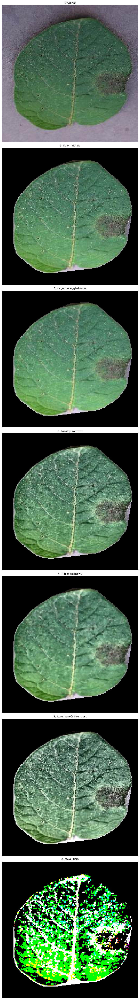

In [37]:
recommended_results = [
    preprocess_images([image], settings)[0]
    for settings in recommended_settings.values()
]

fig, axes = plt.subplots(7, 1, figsize=(30, 58))
for ax, result, title in zip(
    axes,
    [image] + recommended_results,
    ["Oryginał"] + list(recommended_settings),
):
    ax.imshow(result)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()
